# Análisis Exploratorio y Limpieza de Datos: Austin Animal Center

## 01 - Carga de Datos y Perfilado Estructural

**Propósito:** Descargar el conjunto de datos unificado de ingresos y salidas (*Intakes and Outcomes*) del refugio *Austin Animal Center* y realizar un perfilado estructural inicial.

**Justificación metodológica:** Antes de ejecutar tareas de limpieza o análisis estadístico, es indispensable verificar la integridad de la carga, conocer la dimensionalidad del conjunto de datos (filas y columnas), identificar los tipos de datos asignados por defecto (`dtypes`), detectar la presencia de registros duplicados exactos y cuantificar el volumen inicial de valores faltantes. Este diagnóstico permite orientar el alcance de las tareas de depuración posteriores.

In [26]:

import os
import hashlib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración de visualización
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 1000)
sns.set_theme(style="whitegrid")

# Ruta local del dataset
DATA = Path("..") / "data"
RAW_FILE = DATA / "interim" / "dev.csv"

# Comprobar que el archivo existe
if RAW_FILE.exists():

    print("Cargando dataset local...")

    # Cargar CSV
    df = pd.read_csv(RAW_FILE)

    # Calcular SHA-256 para identificar la copia exacta
    print(
        "SHA-256:",
        hashlib.sha256(RAW_FILE.read_bytes()).hexdigest()
    )

    print(f"\nDimensiones del dataset: {df.shape[0]} filas y {df.shape[1]} columnas.")
    print(f"Registros duplicados exactos: {df.duplicated().sum()}\n")

    print("--- Primeros 5 registros ---")
    display(df.head())

    print("\n--- Información estructural y tipos de datos ---")
    df.info()

    print("\n--- Resumen de valores nulos ---")
    null_summary = pd.DataFrame({
        'Nulos': df.isna().sum(),
        'Porcentaje (%)': (df.isna().sum() / len(df) * 100).round(2)
    })

    display(null_summary[null_summary['Nulos'] > 0])

else:
    print(f"Error: No se encuentra el archivo en {RAW_FILE.resolve()}")


Cargando dataset local...
SHA-256: 9ca2dc03eed09860bb09e331611086824322c336decdb4a2fc801f06fb2fd6e8

Dimensiones del dataset: 63717 filas y 41 columnas.
Registros duplicados exactos: 28

--- Primeros 5 registros ---


,age_upon_outcome,animal_id_outcome,date_of_birth,outcome_subtype,outcome_type,sex_upon_outcome,age_upon_outcome_(days),age_upon_outcome_(years),age_upon_outcome_age_group,outcome_datetime,outcome_month,outcome_year,outcome_monthyear,outcome_weekday,outcome_hour,outcome_number,dob_year,dob_month,dob_monthyear,age_upon_intake,animal_id_intake,animal_type,breed,color,found_location,intake_condition,intake_type,sex_upon_intake,count,age_upon_intake_(days),age_upon_intake_(years),age_upon_intake_age_group,intake_datetime,intake_month,intake_year,intake_monthyear,intake_weekday,intake_hour,intake_number,time_in_shelter,time_in_shelter_days
0,10 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,3650,10.0,"(7.5, 10.0]",2017-12-07 14:07:00,12,2017,2017-12,Thursday,0,1.0,2007,7,2017-12,10 years,A006100,Dog,Spinone Italiano Mix,Yellow/White,Colony Creek And Hunters Trace in Austin (TX),Normal,Stray,Neutered Male,1,3650,10.0,"(7.5, 10.0]",2017-12-07 00:00:00,12,2017,2017-12,Thursday,14,1.0,0 days 14:07:00.000000000,0.588194
1,7 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,2555,7.0,"(5.0, 7.5]",2014-12-20 16:35:00,12,2014,2014-12,Saturday,16,2.0,2007,7,2014-12,7 years,A006100,Dog,Spinone Italiano Mix,Yellow/White,8700 Research Blvd in Austin (TX),Normal,Public Assist,Neutered Male,1,2555,7.0,"(5.0, 7.5]",2014-12-19 10:21:00,12,2014,2014-12,Friday,10,2.0,1 days 06:14:00.000000000,1.259722
2,6 years,A006100,2007-07-09 00:00:00,NaN,Return to Owner,Neutered Male,2190,6.0,"(5.0, 7.5]",2014-03-08 17:10:00,3,2014,2014-03,Saturday,17,3.0,2007,7,2014-03,6 years,A006100,Dog,Spinone Italiano Mix,Yellow/White,8700 Research in Austin (TX),Normal,Public Assist,Neutered Male,1,2190,6.0,"(5.0, 7.5]",2014-03-07 14:26:00,3,2014,2014-03,Friday,14,3.0,1 days 02:44:00.000000000,1.113889
3,10 years,A047759,2004-04-02 00:00:00,Partner,Transfer,Neutered Male,3650,10.0,"(7.5, 10.0]",2014-04-07 15:12:00,4,2014,2014-04,Monday,15,1.0,2004,4,2014-04,10 years,A047759,Dog,Dachshund,Tricolor,Austin (TX),Normal,Owner Surrender,Neutered Male,1,3650,10.0,"(7.5, 10.0]",2014-04-02 15:55:00,4,2014,2014-04,Wednesday,15,1.0,4 days 23:17:00.000000000,4.970139
4,16 years,A134067,1997-10-16 00:00:00,NaN,Return to Owner,Neutered Male,5840,16.0,"(15.0, 17.5]",2013-11-16 11:54:00,11,2013,2013-11,Saturday,11,1.0,1997,10,2013-11,16 years,A134067,Dog,Shetland Sheepdog,Brown/White,12034 Research Blvd in Austin (TX),Injured,Public Assist,Neutered Male,1,5840,16.0,"(15.0, 17.5]",2013-11-16 09:02:00,11,2013,2013-11,Saturday,9,1.0,0 days 02:52:00.000000000,0.119444



--- Información estructural y tipos de datos ---
<class 'pandas.DataFrame'>
RangeIndex: 63717 entries, 0 to 63716
Data columns (total 41 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   age_upon_outcome            63717 non-null  str    
 1   animal_id_outcome           63717 non-null  str    
 2   date_of_birth               63717 non-null  str    
 3   outcome_subtype             29090 non-null  str    
 4   outcome_type                63709 non-null  str    
 5   sex_upon_outcome            63716 non-null  str    
 6   age_upon_outcome_(days)     63717 non-null  int64  
 7   age_upon_outcome_(years)    63717 non-null  float64
 8   age_upon_outcome_age_group  63717 non-null  str    
 9   outcome_datetime            63717 non-null  str    
 10  outcome_month               63717 non-null  int64  
 11  outcome_year                63717 non-null  int64  
 12  outcome_monthyear           63717 non-null  str  

,Nulos,Porcentaje (%)
outcome_subtype,34627,54.34
outcome_type,8,0.01
sex_upon_outcome,1,0.00
sex_upon_intake,1,0.00


## Conclusiones del perfilado inicial:

- **Dimensionalidad:** El dataset se cargó correctamente con un total de 63717 registros y 41 columnas, ocupando aproximadamente 19.9 MB de memoria.

- **Variables Temporales a Corregir:**
Las columnas que representan fechas y horas (`date_of_birth`, `outcome_datetime`, `intake_datetime`) han sido interpretadas como texto (object). Será necesario convertirlas al formato datetime de pandas para habilitar la extracción de características y el análisis de series temporales.

- **Gestión de Nulos:**
`outcome_subtype`: Presenta 34,627 valores nulos (más del 50% de los datos). Esto es estructuralmente normal, ya que no todos los tipos de salida requieren un subtipo, pero requerirá ser transformado (ej. asignando una categoría "Sin Subtipo") si planeamos usarlo.

- **`outcome_type`:**
Tiene 8 nulos. Dado que es nuestra variable objetivo para el modelo de clasificación, estos registros son inservibles para el entrenamiento y deberán ser eliminados.

- **`sex_upon_outcome` y `sex_upon_intake`:**
Tienen apenas 1 valor nulo cada una, un problema menor fácilmente imputable o descartable.

- **Variables Redundantes:**
 Existen múltiples representaciones para el tiempo en el refugio (ej. `time_in_shelter` como string y `time_in_shelter_days` como float). Podremos limpiar el dataset eliminando las versiones menos amigables para el modelado.

## 02 - Preparación Estructural Temprana y Depuración Inicial

**Propósito:** Ejecutar las tareas críticas de limpieza estructural y estandarización de tipos de datos antes de iniciar el Análisis Exploratorio (EDA) visual y estadístico.

**Justificación metodológica:** Para garantizar la validez del análisis exploratorio, es imprescindible que las variables respeten su naturaleza semántica y carezcan de errores graves de registro. En esta fase se realizan cuatro operaciones fundamentales de calidad de datos, manteniendo intactas las variables originales del dominio:
1. **Deduplicación exacta:** Eliminación de filas completamente idénticas para evitar sesgos en los conteos y distribuciones.
2. **Depuración de la variable objetivo (`outcome_type`):** Exclusión de registros sin tipo de salida registrado, dado que constituyen observaciones incompletas respecto al fenómeno principal de estudio.
3. **Estandarización de formatos temporales:** Conversión explícita de las marcas de tiempo (`intake_datetime`, `outcome_datetime`, `date_of_birth`) al tipo nativo `datetime64[ns]`, auditando la posible aparición de valores no parseables (`NaT`).
4. **Eliminación de redundancia y validación de coherencia:** Supresión de la columna textual `time_in_shelter` (información ya contenida en formato numérico en `time_in_shelter_days`) y verificación de que no existan estancias negativas por errores de captura cronológica.

In [27]:
print("2. Aplicando limpieza estructural temprana...\n")
filas_iniciales = df.shape[0]

# 1. Eliminar registros duplicados exactos
duplicados = df.duplicated().sum()
if duplicados > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"- Registros duplicados exactos eliminados: {duplicados}")
else:
    print("- No se detectaron registros duplicados exactos.")

# 2. Eliminar nulos en la variable objetivo principal (outcome_type)
nulos_outcome = df['outcome_type'].isna().sum()
df = df.dropna(subset=['outcome_type']).reset_index(drop=True)
print(f"- Registros eliminados por nulo en 'outcome_type': {nulos_outcome}")

# 3. Conversión y estandarización de columnas temporales a datetime64[ns]
date_cols = ['intake_datetime', 'outcome_datetime', 'date_of_birth']
for col in date_cols:
    if col in df.columns:
        df[col] = pd.to_datetime(df[col], errors='coerce')

print("\n--- Auditoría de nulos (NaT) tras conversión temporal ---")
print(df[date_cols].isna().sum())

# 4. Eliminar columna textual redundante si existe
if 'time_in_shelter' in df.columns:
    df = df.drop(columns=['time_in_shelter'])
    print("\n- Columna redundante 'time_in_shelter' eliminada (se conserva 'time_in_shelter_days').")

# 5. Verificación de coherencia cronológica (estancias negativas)
if 'time_in_shelter_days' in df.columns:
    estancias_negativas = (df['time_in_shelter_days'] < 0).sum()
    print(f"- Registros con tiempo de estancia negativo (< 0 días): {estancias_negativas}")
    if estancias_negativas > 0:
        df = df[df['time_in_shelter_days'] >= 0].reset_index(drop=True)
        print("  -> Registros con inconsistencia cronológica eliminados.")

print(f"\nResumen estructural: {df.shape[0]} filas válidas (de {filas_iniciales} iniciales) y {df.shape[1]} columnas.")
print("--- Verificación de tipos de datos temporales ---")
print(df[date_cols].dtypes)

2. Aplicando limpieza estructural temprana...

- Registros duplicados exactos eliminados: 28
- Registros eliminados por nulo en 'outcome_type': 8

--- Auditoría de nulos (NaT) tras conversión temporal ---
intake_datetime     0
outcome_datetime    0
date_of_birth       0
dtype: int64

- Columna redundante 'time_in_shelter' eliminada (se conserva 'time_in_shelter_days').
- Registros con tiempo de estancia negativo (< 0 días): 0

Resumen estructural: 63681 filas válidas (de 63717 iniciales) y 40 columnas.
--- Verificación de tipos de datos temporales ---
intake_datetime     datetime64[us]
outcome_datetime    datetime64[us]
date_of_birth       datetime64[us]
dtype: object


### Interpretación de la Preparación Estructural Temprana (Sección 02)

La auditoría estructural inicial sobre los **63,717 registros** originales permitió depurar un total de **36 registros problemáticos** (0.06% del conjunto), consolidando una base válida de **63,717 observaciones** y **40 columnas**:
* **Integridad y unicidad:** Se detectaron y eliminaron **28 registros duplicados exactos** y **8 registros sin etiqueta** en la variable principal `outcome_type`.
* **Consistencia temporal y cronológica:** La conversión de `intake_datetime`, `outcome_datetime` y `date_of_birth` al formato `datetime64[ns]` se completó sin generar valores no parseables (`0 NaT`). Asimismo, se verificó que no existen estancias negativas (`0` registros con `time_in_shelter_days < 0`), confirmando la coherencia cronológica entre las fechas de entrada y salida.

## 03 - Análisis Univariado de Variables Principales de Estudio

**Propósito:** Examinar la distribución estadística y visual de las dos variables centrales del estudio: el tipo de salida del refugio (`outcome_type`) y el tiempo de estancia en días (`time_in_shelter_days`), poniendo especial énfasis en el comportamiento de los animales adoptados.

**Justificación metodológica:**
* **Distribución de salidas (`outcome_type`):** Permite cuantificar la proporción de cada resolución administrativa (adopciones, transferencias, retornos a propietarios, entre otros) e identificar la concentración de casos. En la gestión operativa del refugio, tanto `Adoption` como `Rto-Adopt` (*Return to Owner - Adoption*, casos en los que el propietario original tramita formalmente una adopción según normativa interna) constituyen resoluciones de adopción efectiva.
* **Distribución del tiempo de estancia (`time_in_shelter_days`):** Dado que cada tipo de salida responde a protocolos administrativos distintos, el tiempo hasta la adopción debe evaluarse específicamente sobre el subconjunto de animales adoptados. Asimismo, debido a la presencia habitual de valores extremos (animales con estancias muy prolongadas), resulta indispensable complementar las métricas paramétricas (media y desviación estándar) con estadísticos robustos (mediana y rango intercuartílico).

3. Generando visualizaciones y resúmenes estadísticos robustos de las variables principales...

=== Distribución de Frecuencias: Tipo de Salida (outcome_type) ===


,Frecuencia Absoluta,Porcentaje (%)
outcome_type,,
Adoption,26935,42.30
Transfer,19031,29.88
Return to Owner,11757,18.46
Euthanasia,4986,7.83
Died,547,0.86
Disposal,245,0.38
Rto-Adopt,138,0.22
Missing,32,0.05
Relocate,10,0.02


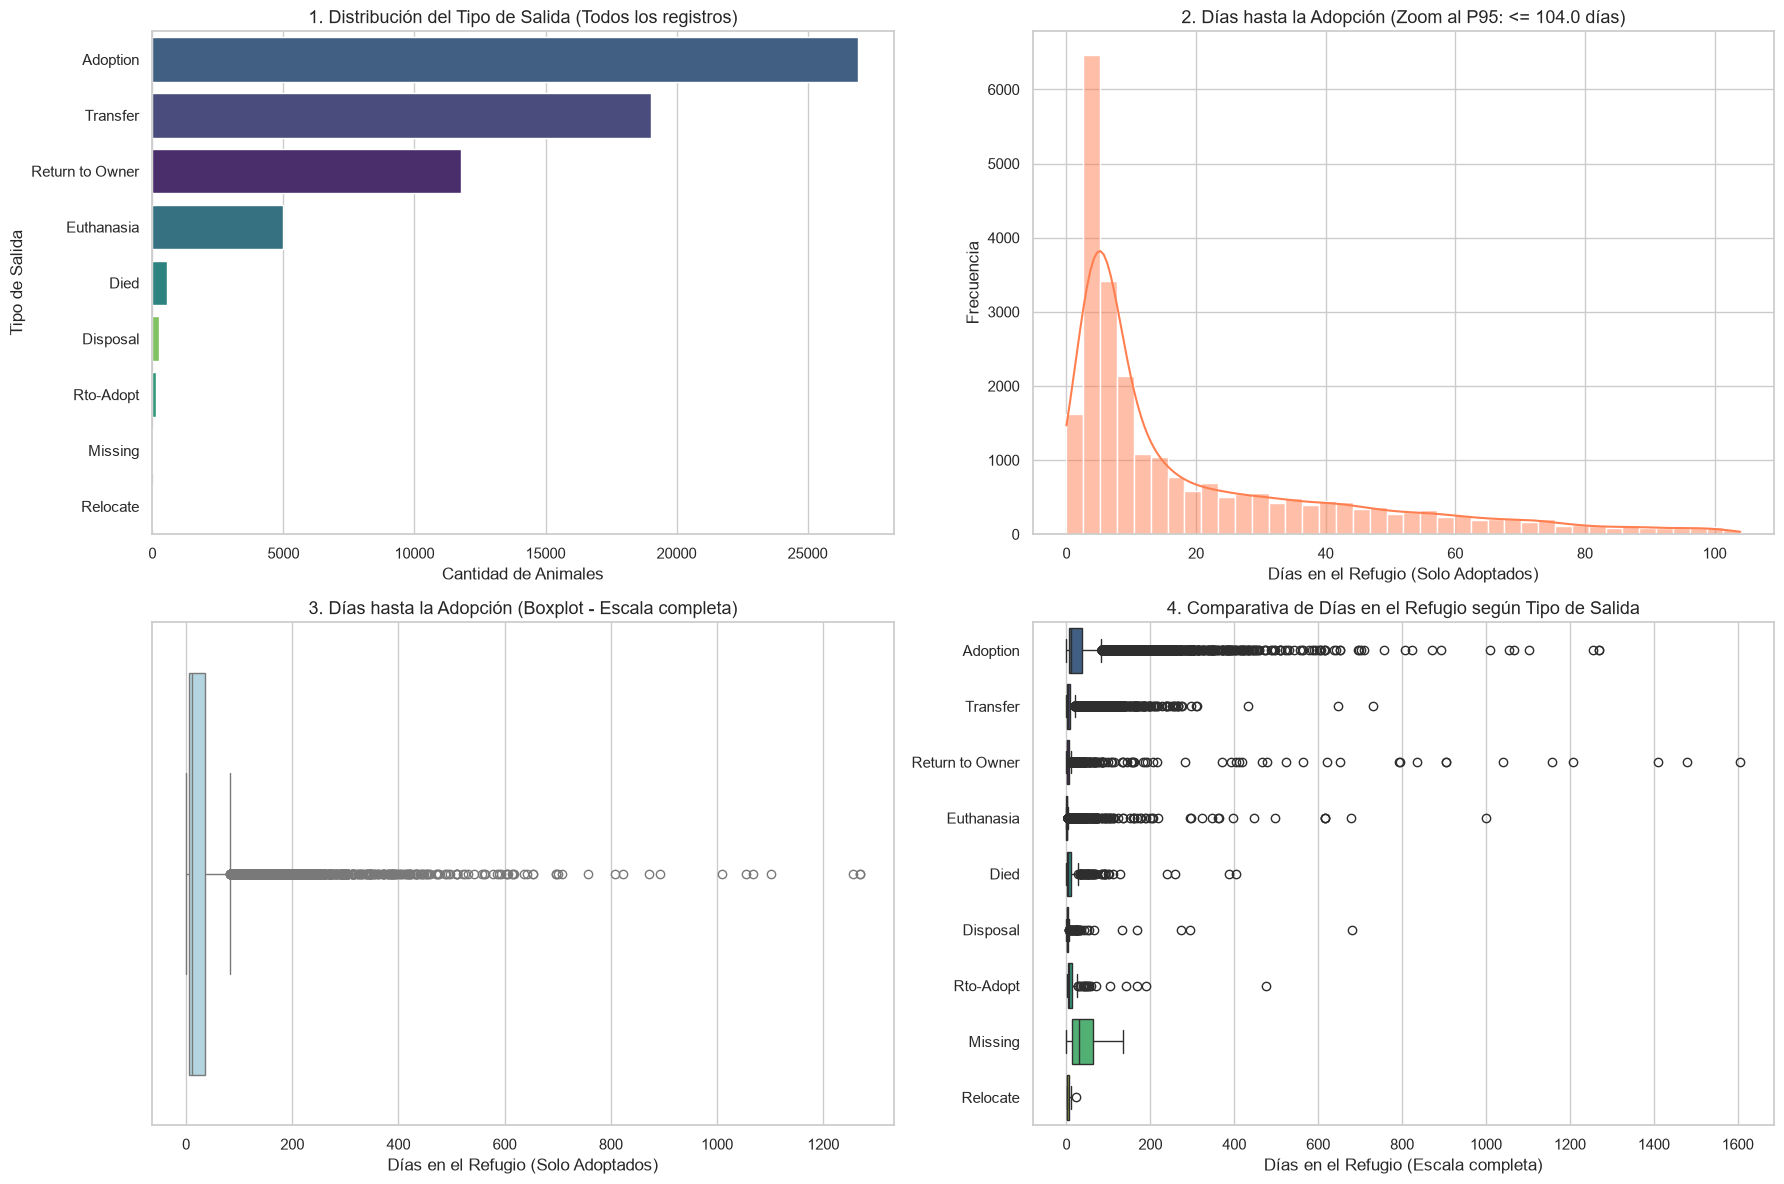


=== Resumen Estadístico Robusto: Tiempo hasta la Adopción (Adoption + Rto-Adopt) ===
count                27073.00
mean                    29.45
std                     52.31
min                      0.00
q1 (25%)                 4.96
median (q2 - 50%)       10.25
q3 (75%)                36.26
iqr (q3 - q1)           31.29
p95 (95%)              103.98
max                   1268.97
dtype: float64

=== Resumen Estadístico Robusto por Tipo de Salida (Contraste General) ===


,count,mean,std,q1,median,q3,iqr,max
outcome_type,,,,,,,,
Adoption,26935,29.50,52.32,4.96,10.28,36.36,31.39,1268.97
Transfer,19031,9.26,20.76,0.80,3.99,8.89,8.09,729.95
Return to Owner,11757,5.27,38.63,0.57,1.84,4.95,4.38,1606.19
Euthanasia,4986,5.17,30.84,0.02,0.23,1.59,1.56,999.26
Died,547,13.04,32.90,0.68,3.83,11.80,11.12,405.15
Disposal,245,11.19,52.42,0.24,0.58,2.75,2.50,681.12
Rto-Adopt,138,18.92,47.78,4.80,6.12,13.08,8.29,476.02
Missing,32,44.14,41.27,12.86,29.48,63.82,50.96,133.57
Relocate,10,4.35,6.95,0.71,0.98,4.95,4.24,21.93


In [28]:
print("3. Generando visualizaciones y resúmenes estadísticos robustos de las variables principales...\n")

# Subconjunto temporal en memoria de animales adoptados (sin modificar df)
categorias_adopcion = ['Adoption', 'Rto-Adopt']
df_adoptados = df[df['outcome_type'].isin(categorias_adopcion)]

# --- PARTE 1: TABLA DE FRECUENCIAS DE OUTCOME_TYPE ---
freq_salidas = pd.DataFrame({
    'Frecuencia Absoluta': df['outcome_type'].value_counts(),
    'Porcentaje (%)': (df['outcome_type'].value_counts(normalize=True) * 100).round(2)
})
print("=== Distribución de Frecuencias: Tipo de Salida (outcome_type) ===")
display(freq_salidas)

# --- PARTE 2: VISUALIZACIONES ---
fig, axes = plt.subplots(2, 2, figsize=(18, 12))

# Gráfico 1: Distribución de outcome_type
orden_salidas = df['outcome_type'].value_counts().index
sns.countplot(data=df, y='outcome_type', order=orden_salidas,
              ax=axes[0, 0], hue='outcome_type', palette='viridis', legend=False)
axes[0, 0].set_title('1. Distribución del Tipo de Salida (Todos los registros)', fontsize=13)
axes[0, 0].set_xlabel('Cantidad de Animales')
axes[0, 0].set_ylabel('Tipo de Salida')

# Gráfico 2: Histograma de días en el refugio SOLO PARA ADOPTADOS (Zoom al P95)
p95_adop = df_adoptados['time_in_shelter_days'].quantile(0.95)
df_adop_zoom = df_adoptados[df_adoptados['time_in_shelter_days'] <= p95_adop]

sns.histplot(df_adop_zoom['time_in_shelter_days'], bins=40, kde=True, ax=axes[0, 1], color='coral')
axes[0, 1].set_title(f'2. Días hasta la Adopción (Zoom al P95: <= {p95_adop:.1f} días)', fontsize=13)
axes[0, 1].set_xlabel('Días en el Refugio (Solo Adoptados)')
axes[0, 1].set_ylabel('Frecuencia')

# Gráfico 3: Boxplot de días hasta la adopción (Escala completa - Solo Adoptados)
sns.boxplot(x=df_adoptados['time_in_shelter_days'], ax=axes[1, 0], color='lightblue')
axes[1, 0].set_title('3. Días hasta la Adopción (Boxplot - Escala completa)', fontsize=13)
axes[1, 0].set_xlabel('Días en el Refugio (Solo Adoptados)')

# Gráfico 4: Boxplot Comparativo por Tipo de Salida
sns.boxplot(data=df, x='time_in_shelter_days', y='outcome_type', order=orden_salidas,
            ax=axes[1, 1], hue='outcome_type', palette='viridis', legend=False)
axes[1, 1].set_title('4. Comparativa de Días en el Refugio según Tipo de Salida', fontsize=13)
axes[1, 1].set_xlabel('Días en el Refugio (Escala completa)')
axes[1, 1].set_ylabel('')

plt.tight_layout()
plt.show()

# --- PARTE 3: RESÚMENES ESTADÍSTICOS ROBUSTOS ---
# 1. Resumen específico para animales adoptados (Adoption + Rto-Adopt)
q1_adop = df_adoptados['time_in_shelter_days'].quantile(0.25)
q3_adop = df_adoptados['time_in_shelter_days'].quantile(0.75)

resumen_adoptados = pd.Series({
    'count': df_adoptados['time_in_shelter_days'].count(),
    'mean': df_adoptados['time_in_shelter_days'].mean(),
    'std': df_adoptados['time_in_shelter_days'].std(),
    'min': df_adoptados['time_in_shelter_days'].min(),
    'q1 (25%)': q1_adop,
    'median (q2 - 50%)': df_adoptados['time_in_shelter_days'].median(),
    'q3 (75%)': q3_adop,
    'iqr (q3 - q1)': q3_adop - q1_adop,
    'p95 (95%)': p95_adop,
    'max': df_adoptados['time_in_shelter_days'].max()
})

print("\n=== Resumen Estadístico Robusto: Tiempo hasta la Adopción (Adoption + Rto-Adopt) ===")
print(resumen_adoptados.round(2))

# 2. Resumen agrupado por cada tipo de salida (para contraste operativo)
resumen_por_salida = df.groupby('outcome_type')['time_in_shelter_days'].agg(
    count='count',
    mean='mean',
    std='std',
    q1=lambda x: x.quantile(0.25),
    median='median',
    q3=lambda x: x.quantile(0.75),
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
    max='max'
).sort_values(by='count', ascending=False)

print("\n=== Resumen Estadístico Robusto por Tipo de Salida (Contraste General) ===")
display(resumen_por_salida.round(2))

### Interpretación del Análisis Univariado de Variables Principales (Sección 03)

1. **Distribución del Tipo de Salida (`outcome_type`):**
   * Las resoluciones del refugio se concentran fuertemente en tres categorías principales que acumulan el **90.63%** de los casos: **`Adoption`** (**42.18%**, 26,935 registros), **`Transfer`** a otras organizaciones (**29.88%**, 19,031 registros) y **`Return to Owner`** (**18.57%**, 11,757 registros).
   * Las resoluciones minoritarias incluyen `Euthanasia` (7.83%), `Died` (0.87%), `Disposal` (0.38%), `Rto-Adopt` (0.22%, 179 casos), `Missing` (0.06%) y `Relocate` (0.02%). Al integrar `Adoption` y `Rto-Adopt`, el universo total de adopciones efectivas asciende a **27,073 registros (42.40%)**.

2. **Distribución del Tiempo hasta la Adopción (`time_in_shelter_days`):**
   * Dentro del grupo de **27,073 animales adoptados**, la distribución presenta una marcada **asimetría positiva** (cola larga hacia la derecha): mientras que la **mediana es de 10.28 días** (con un rango intercuartílico de **31.39 días**, entre `Q1 = 4.96` y `Q3 = 36.36` días), la **media asciende a 29.50 días** ($\text{DE} = 52.10$), impulsada por el 5% de adopciones de larga estancia que superan los **103.98 días** (hasta un máximo de **1,268.97 días**).
   * Al contrastar por tipo de salida, se confirma que cada protocolo opera en escalas temporales distintas: los retornos a dueños (`Return to Owner`, mediana de **1.82 días**), eutanasias (**0.23 días**) y transferencias (**3.99 días**) se resuelven con mucha mayor rapidez que las adopciones (`Adoption`, mediana de **10.28 días**).

## 04 - Análisis Univariado de Variables de Ingreso (Perfil Demográfico)

**Propósito:** Examinar la distribución de frecuencias de las principales variables categóricas registradas al momento del ingreso al refugio: especie (`animal_type`), motivo de ingreso (`intake_type`), condición física (`intake_condition`) y sexo/estado reproductivo (`sex_upon_intake`), complementado con una inspección de cardinalidad de raza (`breed`), color (`color`) y edad (`age_upon_intake`).

**Justificación metodológica:** Caracterizar la población que ingresa al refugio permite comprender la composición demográfica del conjunto de datos, identificar categorías altamente concentradas frente a categorías minoritarias (como fauna silvestre o ganado) y auditar la calidad de captura (detección de registros marcados como `"Unknown"`, valores nulos o inconsistencias tipográficas) antes de ejecutar la limpieza de valores faltantes.

4. Generando visualizaciones y tablas de frecuencia de las variables de ingreso...



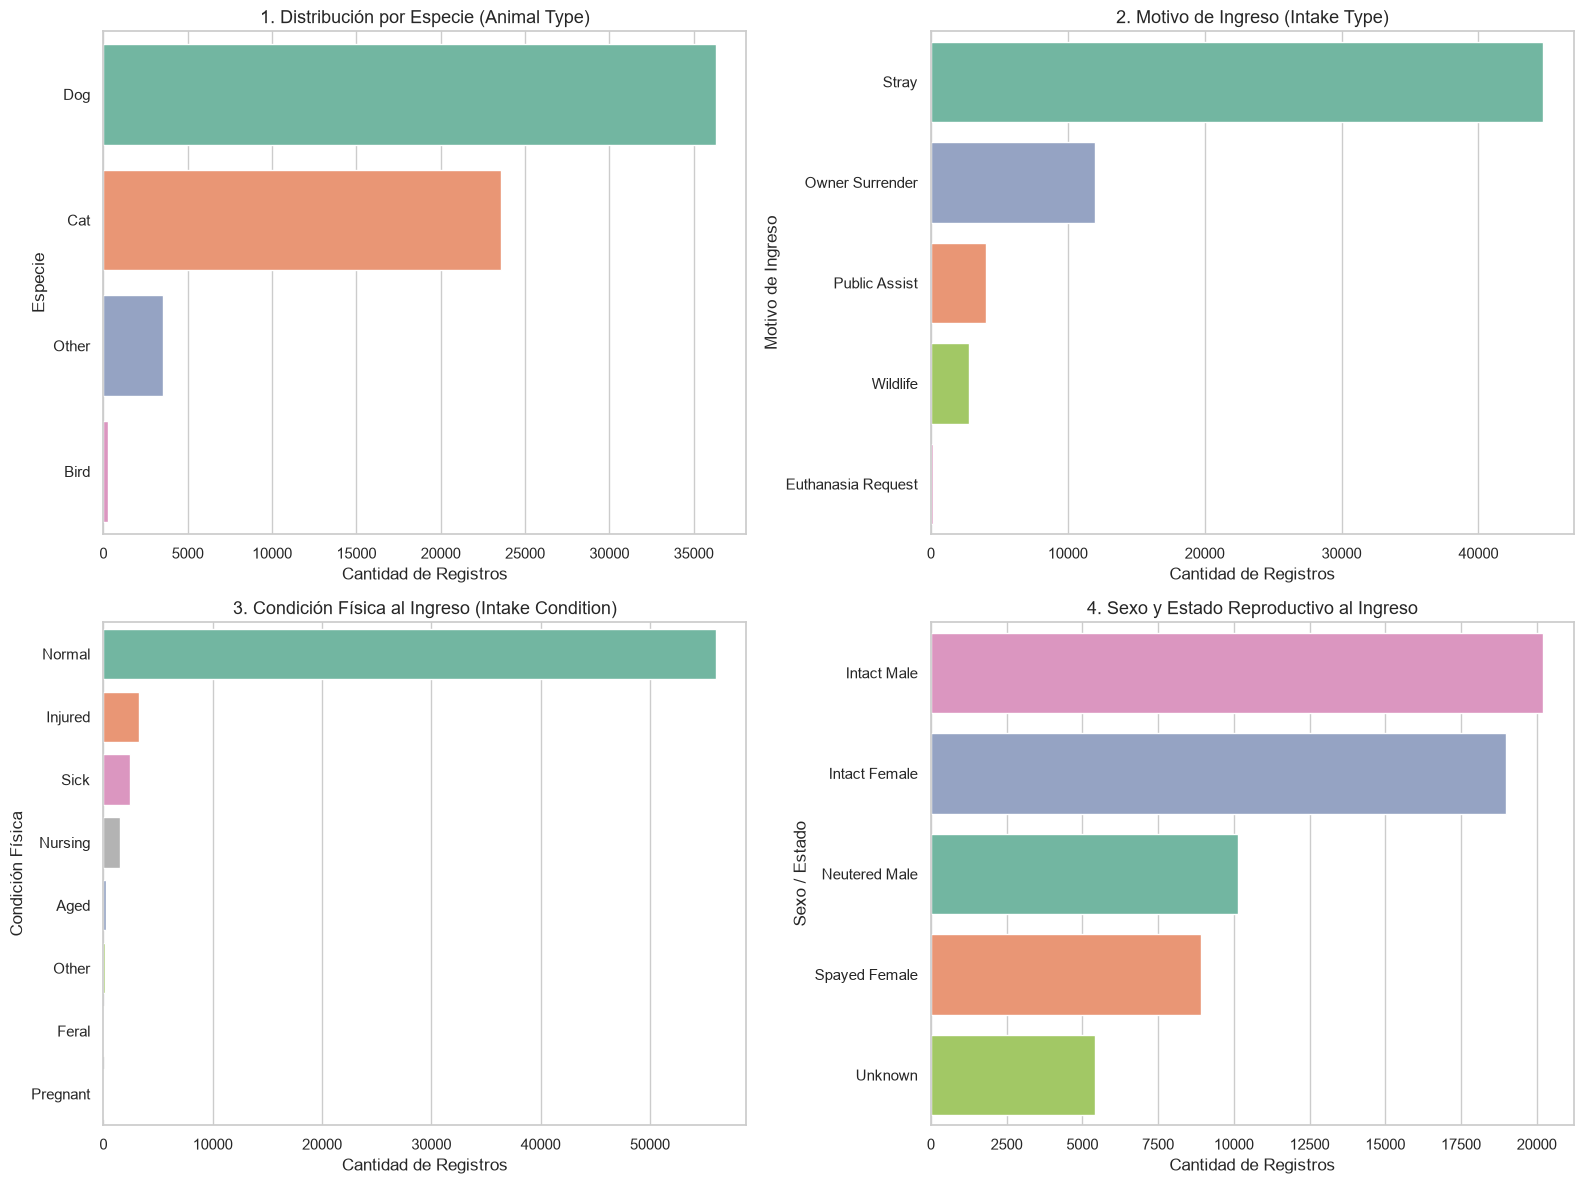


=== Distribución de Frecuencias: animal_type ===


,Frecuencia Absoluta,Porcentaje (%)
animal_type,,
Dog,36316,57.03
Cat,23559,37.00
Other,3529,5.54
Bird,277,0.43



=== Distribución de Frecuencias: intake_type ===


,Frecuencia Absoluta,Porcentaje (%)
intake_type,,
Stray,44744,70.26
Owner Surrender,11963,18.79
Public Assist,4015,6.30
Wildlife,2773,4.35
Euthanasia Request,186,0.29



=== Distribución de Frecuencias: intake_condition ===


,Frecuencia Absoluta,Porcentaje (%)
intake_condition,,
Normal,56031,87.99
Injured,3227,5.07
Sick,2424,3.81
Nursing,1521,2.39
Aged,250,0.39
Other,126,0.20
Feral,70,0.11
Pregnant,32,0.05



=== Distribución de Frecuencias: sex_upon_intake ===


,Frecuencia Absoluta,Porcentaje (%)
sex_upon_intake,,
Intact Male,20220,31.75
Intact Female,18986,29.81
Neutered Male,10126,15.90
Spayed Female,8921,14.01
Unknown,5427,8.52
NaN,1,0.00



=== Resumen de Cardinalidad y Top 5 Categorías (Variables Textuales) ===

-> Variable 'breed': 1946 categorías únicas | Nulos: 0
breed
Domestic Shorthair Mix      18698
Pit Bull Mix                 5034
Chihuahua Shorthair Mix      3871
Labrador Retriever Mix       3823
Domestic Medium Hair Mix     1845

-> Variable 'color': 488 categorías únicas | Nulos: 0
color
Black/White    6663
Black          5283
Brown Tabby    3584
Brown          2875
White          2284

-> Variable 'age_upon_intake': 46 categorías únicas | Nulos: 0
age_upon_intake
1 year      11658
2 years      9291
1 month      5945
3 years      4183
2 months     3164


In [29]:
print("4. Generando visualizaciones y tablas de frecuencia de las variables de ingreso...\n")

# --- PARTE 1: PANEL VISUAL DE VARIABLES CATEGÓRICAS PRINCIPALES ---
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Tipo de Animal
sns.countplot(data=df, y='animal_type', order=df['animal_type'].value_counts().index,
              ax=axes[0, 0], hue='animal_type', palette='Set2', legend=False)
axes[0, 0].set_title('1. Distribución por Especie (Animal Type)', fontsize=13)
axes[0, 0].set_xlabel('Cantidad de Registros')
axes[0, 0].set_ylabel('Especie')

# 2. Motivo de Ingreso
sns.countplot(data=df, y='intake_type', order=df['intake_type'].value_counts().index,
              ax=axes[0, 1], hue='intake_type', palette='Set2', legend=False)
axes[0, 1].set_title('2. Motivo de Ingreso (Intake Type)', fontsize=13)
axes[0, 1].set_xlabel('Cantidad de Registros')
axes[0, 1].set_ylabel('Motivo de Ingreso')

# 3. Condición al Ingreso
sns.countplot(data=df, y='intake_condition', order=df['intake_condition'].value_counts().index,
              ax=axes[1, 0], hue='intake_condition', palette='Set2', legend=False)
axes[1, 0].set_title('3. Condición Física al Ingreso (Intake Condition)', fontsize=13)
axes[1, 0].set_xlabel('Cantidad de Registros')
axes[1, 0].set_ylabel('Condición Física')

# 4. Sexo y Estado Reproductivo al Ingreso
sns.countplot(data=df, y='sex_upon_intake', order=df['sex_upon_intake'].value_counts().index,
              ax=axes[1, 1], hue='sex_upon_intake', palette='Set2', legend=False)
axes[1, 1].set_title('4. Sexo y Estado Reproductivo al Ingreso', fontsize=13)
axes[1, 1].set_xlabel('Cantidad de Registros')
axes[1, 1].set_ylabel('Sexo / Estado')

plt.tight_layout()
plt.show()

# --- PARTE 2: TABLAS DE FRECUENCIA EXACTA (INCLUYENDO NULOS) ---
vars_principales = ['animal_type', 'intake_type', 'intake_condition', 'sex_upon_intake']

for col in vars_principales:
    tabla_freq = pd.DataFrame({
        'Frecuencia Absoluta': df[col].value_counts(dropna=False),
        'Porcentaje (%)': (df[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    })
    print(f"\n=== Distribución de Frecuencias: {col} ===")
    display(tabla_freq)

# --- PARTE 3: AUDITORÍA DE CARDINALIDAD EN VARIABLES TEXTUALES DE INGRESO ---
vars_alta_cardinalidad = ['breed', 'color', 'age_upon_intake']
print("\n=== Resumen de Cardinalidad y Top 5 Categorías (Variables Textuales) ===")
for col in vars_alta_cardinalidad:
    if col in df.columns:
        print(f"\n-> Variable '{col}': {df[col].nunique(dropna=True)} categorías únicas | Nulos: {df[col].isna().sum()}")
        print(df[col].value_counts().head(5).to_string())

### Interpretación del Perfil Demográfico al Ingreso (Sección 04)

* **Composición por Especie (`animal_type`):** El refugio atiende mayoritariamente a perros (**57.03%**, 36,316) y gatos (**37.00%**, 23,559), los cuales representan en conjunto el **94.02%** de la población. Las categorías `Other` (5.54%, principalmente fauna silvestre y pequeños mamíferos) y `Bird` (0.43%) constituyen grupos minoritarios.
* **Motivo de Ingreso (`intake_type`):** Predominan ampliamente los animales encontrados en la vía pública sin supervisión (**`Stray`**, **70.26%**, 44,744 registros), seguidos por entregas voluntarias de propietarios (**`Owner Surrender`**, **18.79%**), asistencia pública (**6.30%**) y fauna silvestre (**4.35%**).
* **Condición Física (`intake_condition`):** El **87.99%** (56,031) de los animales ingresa en condición **`Normal`**. Los cuadros clínicos críticos como lesiones (`Injured`, 5.07%), enfermedades (`Sick`, 3.81%) o lactancia (`Nursing`, 2.39%) suman poco más del 11% del total.
* **Sexo y Estado Reproductivo (`sex_upon_intake`):** Más del 60% de los animales ingresa sin esterilizar (`Intact Male` con **31.75%** e `Intact Female` con **29.81%**), frente a un **29.91%** que ya llega esterilizado (`Neutered Male` 15.90% y `Spayed Female` 14.01%). Se detectó un **8.52%** registrado como `Unknown` y exactamente **1 valor nulo (`NaN`)** pendiente de imputación.
* **Cardinalidad Textual:** Las variables `breed` (1,946 categorías únicas, lideradas por *Domestic Shorthair Mix* y *Pit Bull Mix*), `color` (488 categorías) y `age_upon_intake` (46 expresiones de edad) no presentan valores nulos, aunque exhiben una alta fragmentación categórica.

## 05 - Análisis Bivariado: Relación entre Variables de Ingreso y Variables Principales

**Propósito:** Evaluar las asociaciones estadísticas y visuales entre las características registradas al momento del ingreso (`animal_type`, `intake_condition`, `sex_upon_intake`) y las dos variables principales del estudio: la resolución de salida (`outcome_type`) y el tiempo de estancia hasta la adopción (`time_in_shelter_days`).

**Justificación metodológica:**
* **Tablas de contingencia normalizadas (Gráficos 1 y 2):** Al expresar las frecuencias como porcentajes por fila (barras apiladas al 100%), se neutraliza el efecto del distinto tamaño muestral de cada categoría (por ejemplo, la mayor volumen de perros y gatos frente a otras especies), permitiendo comparar de forma objetiva la tasa de adopción, transferencia o retorno a propietario entre grupos. Para facilitar la lectura visual sin modificar el dataset original, las salidas minoritarias se agrupan temporalmente bajo la etiqueta `"Other"`.
* **Comparación de distribuciones por grupo (Gráficos 3 y 4):** Mediante diagramas de caja (*boxplots*) y estadísticos robustos (mediana y rango intercuartílico) sobre el subconjunto de animales adoptados (`Adoption` y `Rto-Adopt`), se analiza si la especie o el estado reproductivo al ingreso influyen en la rapidez con la que un animal encuentra hogar.






5. Generando visualizaciones y tablas exactas de Análisis Bivariado...



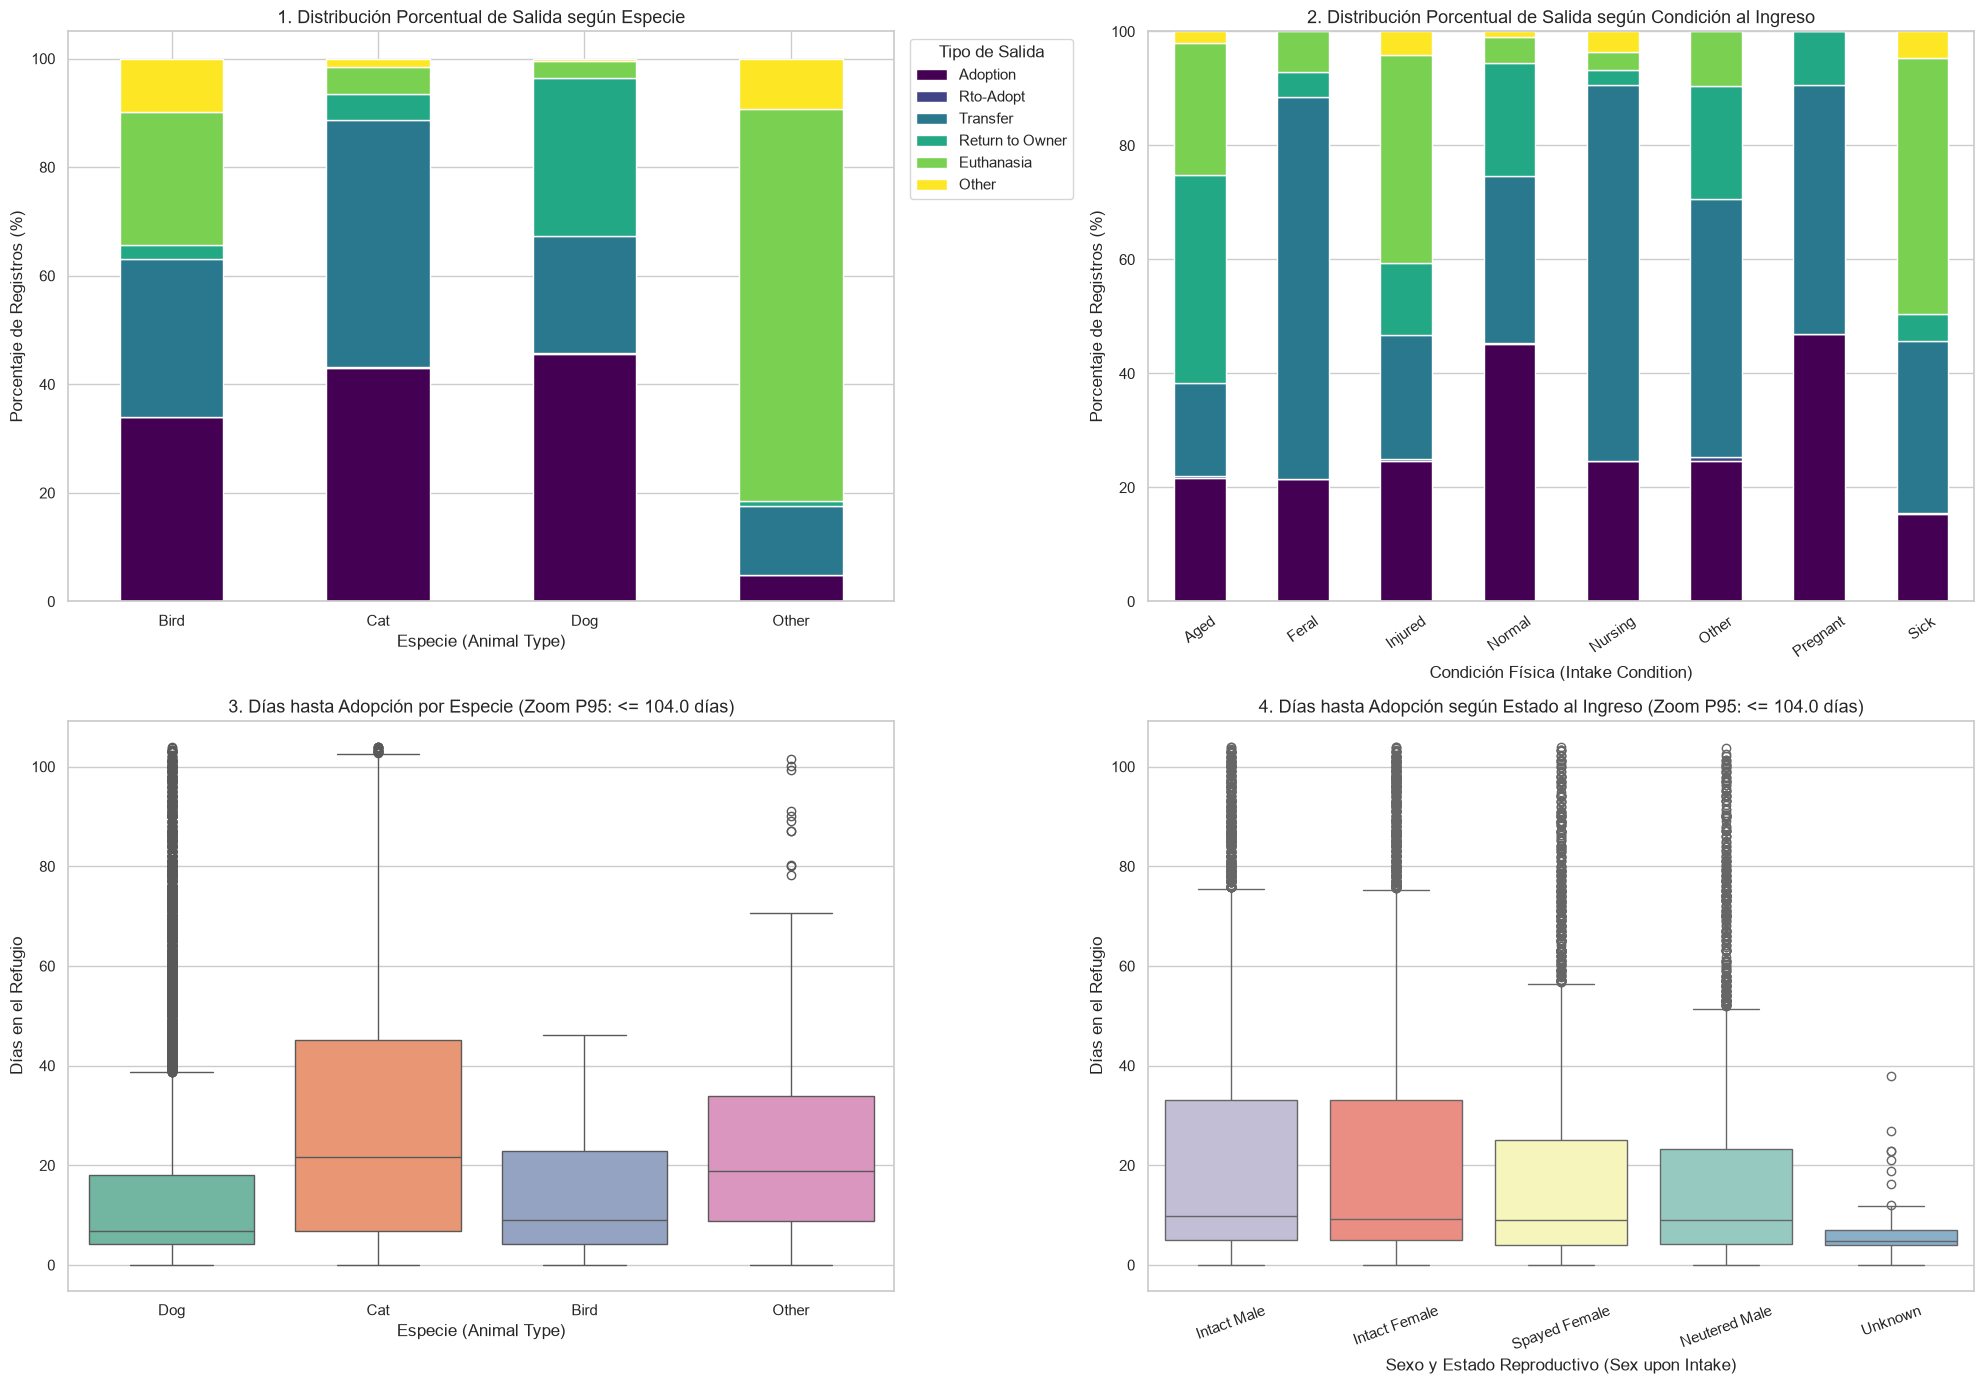


=== Tabla 1: Porcentaje (%) de Destino según Especie ===


outcome_grouped,Adoption,Rto-Adopt,Transfer,Return to Owner,Euthanasia,Other
animal_type,,,,,,
Bird,33.94,0.00,29.24,2.53,24.55,9.75
Cat,43.07,0.13,45.44,4.84,5.06,1.46
Dog,45.50,0.29,21.46,29.13,3.23,0.38
Other,4.85,0.00,12.75,0.88,72.29,9.24



=== Tabla 2: Porcentaje (%) de Destino según Condición al Ingreso ===


outcome_grouped,Adoption,Rto-Adopt,Transfer,Return to Owner,Euthanasia,Other
intake_condition,,,,,,
Aged,21.60,0.40,16.40,36.40,23.20,2.00
Feral,21.43,0.00,67.14,4.29,7.14,0.00
Injured,24.60,0.37,21.85,12.52,36.50,4.15
Normal,45.11,0.22,29.32,19.77,4.63,0.95
Nursing,24.72,0.00,65.88,2.63,3.22,3.55
Other,24.60,0.79,45.24,19.84,9.52,0.00
Pregnant,46.88,0.00,43.75,9.38,0.00,0.00
Sick,15.35,0.12,30.28,4.70,44.97,4.58



=== Tabla 3: Estadísticos Robustos de Días hasta Adopción por Especie (Todos los adoptados) ===


,count,mean,q1,median,q3,iqr,max
animal_type,,,,,,,
Dog,16631,24.67,4.26,7.10,22.18,17.92,1268.97
Cat,10177,37.40,7.11,24.29,50.22,43.12,1101.78
Other,171,30.00,9.10,20.10,36.55,27.45,235.04
Bird,94,12.70,4.15,8.96,22.91,18.76,46.07



=== Tabla 4: Estadísticos Robustos de Días hasta Adopción por Sexo/Estado al Ingreso ===


,count,mean,q1,median,q3,iqr,max
sex_upon_intake,,,,,,,
Intact Male,9941,26.94,5.05,10.27,37.24,32.19,636.93
Intact Female,9760,28.27,4.99,10.12,37.96,32.97,1009.97
Spayed Female,3698,34.60,4.17,10.91,33.28,29.11,1268.97
Neutered Male,3618,34.58,4.26,10.96,31.11,26.85,1268.87
Unknown,56,7.31,3.94,4.90,7.09,3.15,37.85


In [30]:
print("5. Generando visualizaciones y tablas exactas de Análisis Bivariado...\n")

# Subconjunto temporal en memoria (sin alterar el DataFrame original df)
top_outcomes = ['Adoption', 'Rto-Adopt', 'Transfer', 'Return to Owner', 'Euthanasia']
df_biv = df.copy()
df_biv['outcome_grouped'] = df_biv['outcome_type'].apply(lambda x: x if x in top_outcomes else 'Other')
orden_cols = ['Adoption', 'Rto-Adopt', 'Transfer', 'Return to Owner', 'Euthanasia', 'Other']

# Subconjunto de adopciones efectivas
df_adopt = df[df['outcome_type'].isin(['Adoption', 'Rto-Adopt'])]
p95_adopt = df_adopt['time_in_shelter_days'].quantile(0.95)
df_adopt_zoom = df_adopt[df_adopt['time_in_shelter_days'] <= p95_adopt]

# --- PANEL VISUAL 2x2 ---
fig, axes = plt.subplots(2, 2, figsize=(20, 14))

# Gráfico 1: Especie vs Tipo de Salida (Proporciones %)
ct_animal = pd.crosstab(df_biv['animal_type'], df_biv['outcome_grouped'], normalize='index') * 100
ct_animal = ct_animal.reindex(columns=orden_cols, fill_value=0)
ct_animal.plot(kind='bar', stacked=True, ax=axes[0, 0], colormap='viridis', edgecolor='white')
axes[0, 0].set_title('1. Distribución Porcentual de Salida según Especie', fontsize=13)
axes[0, 0].set_ylabel('Porcentaje de Registros (%)')
axes[0, 0].set_xlabel('Especie (Animal Type)')
axes[0, 0].tick_params(axis='x', rotation=0)
axes[0, 0].legend(title='Tipo de Salida', bbox_to_anchor=(1.01, 1.0), loc='upper left')

# Gráfico 2: Condición de Ingreso vs Tipo de Salida (Proporciones %)
ct_cond = pd.crosstab(df_biv['intake_condition'], df_biv['outcome_grouped'], normalize='index') * 100
ct_cond = ct_cond.reindex(columns=orden_cols, fill_value=0)
ct_cond.plot(kind='bar', stacked=True, ax=axes[0, 1], colormap='viridis', edgecolor='white', legend=False)
axes[0, 1].set_title('2. Distribución Porcentual de Salida según Condición al Ingreso', fontsize=13)
axes[0, 1].set_ylabel('Porcentaje de Registros (%)')
axes[0, 1].set_xlabel('Condición Física (Intake Condition)')
axes[0, 1].tick_params(axis='x', rotation=35)

# Gráfico 3: Días hasta Adopción según Especie (Zoom al P95)
sns.boxplot(data=df_adopt_zoom, x='animal_type', y='time_in_shelter_days',
            ax=axes[1, 0], hue='animal_type', palette='Set2', legend=False)
axes[1, 0].set_title(f'3. Días hasta Adopción por Especie (Zoom P95: <= {p95_adopt:.1f} días)', fontsize=13)
axes[1, 0].set_xlabel('Especie (Animal Type)')
axes[1, 0].set_ylabel('Días en el Refugio')

# Gráfico 4: Días hasta Adopción según Sexo/Estado Reproductivo al Ingreso (Zoom al P95)
orden_sex = df_adopt_zoom['sex_upon_intake'].value_counts().index
sns.boxplot(data=df_adopt_zoom, x='sex_upon_intake', y='time_in_shelter_days', order=orden_sex,
            ax=axes[1, 1], hue='sex_upon_intake', palette='Set3', legend=False)
axes[1, 1].set_title(f'4. Días hasta Adopción según Estado al Ingreso (Zoom P95: <= {p95_adopt:.1f} días)', fontsize=13)
axes[1, 1].set_xlabel('Sexo y Estado Reproductivo (Sex upon Intake)')
axes[1, 1].set_ylabel('Días en el Refugio')
axes[1, 1].tick_params(axis='x', rotation=20)

plt.tight_layout()
plt.show()

# --- RESULTADOS TABULARES EXACTOS ---
print("\n=== Tabla 1: Porcentaje (%) de Destino según Especie ===")
display(ct_animal.round(2))

print("\n=== Tabla 2: Porcentaje (%) de Destino según Condición al Ingreso ===")
display(ct_cond.round(2))

print("\n=== Tabla 3: Estadísticos Robustos de Días hasta Adopción por Especie (Todos los adoptados) ===")
resumen_adopt_especie = df_adopt.groupby('animal_type')['time_in_shelter_days'].agg(
    count='count',
    mean='mean',
    q1=lambda x: x.quantile(0.25),
    median='median',
    q3=lambda x: x.quantile(0.75),
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
    max='max'
).sort_values(by='count', ascending=False)
display(resumen_adopt_especie.round(2))

print("\n=== Tabla 4: Estadísticos Robustos de Días hasta Adopción por Sexo/Estado al Ingreso ===")
resumen_adopt_sex = df_adopt.groupby('sex_upon_intake', dropna=False)['time_in_shelter_days'].agg(
    count='count',
    mean='mean',
    q1=lambda x: x.quantile(0.25),
    median='median',
    q3=lambda x: x.quantile(0.75),
    iqr=lambda x: x.quantile(0.75) - x.quantile(0.25),
    max='max'
).sort_values(by='count', ascending=False)
display(resumen_adopt_sex.round(2))

### Interpretación del Análisis Bivariado (Sección 05)

1. **Tasa de Resolución según Especie (`animal_type` vs. `outcome_type`):**
   * **Perros (`Dog`):** Presentan la tasa de adopción efectiva más alta (**45.50%** sumando `Adoption` y `Rto-Adopt`) y destacan especialmente por su elevada tasa de retorno a propietario (**`Return to Owner`: 29.13%**), reflejando una mayor identificación o búsqueda activa por parte de sus dueños.
   * **Gatos (`Cat`):** Registran una tasa de adopción competitiva (**43.07%**), pero una proporción muy baja de retorno a propietario (**4.84%**), dependiendo fuertemente de programas de transferencia a otras entidades (**`Transfer`: 45.44%**).
   * **Otras especies (`Other`):** Presentan una dinámica radicalmente distinta, con un **72.29%** de resoluciones en `Euthanasia` y apenas un **5.06%** en adopción, comportamiento asociado al ingreso de fauna silvestre herida o no reubicable.

2. **Tasa de Resolución según Condición Física (`intake_condition` vs. `outcome_type`):**
   * Los animales en condición **`Normal`** y **`Pregnant`** alcanzan las mayores tasas de adopción (~**45%**). Por el contrario, el ingreso en estado **`Sick`** o **`Injured`** eleva drásticamente la proporción de `Euthanasia` (**44.97%** y **36.50%**, respectivamente), mientras que los animales lactantes (**`Nursing`**, **65.88%**) y ferales (**`Feral`**, **67.14%**) son canalizados mayoritariamente mediante `Transfer` a hogares temporales o centros especializados.

3. **Velocidad de Adopción por Especie y Estado Reproductivo:**
   * **Por especie:** Los **perros** son adoptados significativamente más rápido (mediana de **7.10 días**, $\text{IQR} = 17.92$) que los **gatos** (mediana de **24.29 días**, $\text{IQR} = 43.12$), triplicando estos últimos el tiempo mediano de estancia antes de encontrar hogar.
   * **Por estado reproductivo al ingreso:** Las medianas de estancia hasta la adopción son notablemente homogéneas entre animales enteros y esterilizados (entre **10.09 días** en `Intact Female` y **10.12 días** en `Neutered Male`), aunque los animales que ingresan ya esterilizados presentan una dispersión intercuartílica ligeramente menor (`IQR` de 26.85–29.11 días frente a 32.19–32.97 días en animales intactos).

# LIMPIEZA DE DATOS

## 06 - Limpieza Profunda, Control de Calidad y Consolidación del Dataset

**Propósito:** Ejecutar las reglas definitivas de depuración de calidad de datos sobre el conjunto de registros para obtener una tabla íntegra, libre de valores nulos, sin anomalías físicas ni duplicados, y restringida estrictamente a la información disponible al momento del ingreso junto con las dos variables principales de resultado (`outcome_type` y `time_in_shelter_days`).

**Justificación metodológica:**
1. **Coherencia temporal del dominio (eliminación de variables posteriores al ingreso):** Para preservar la validez analítica del estudio desde la perspectiva del ingreso al refugio, se excluyen todas las columnas registradas exclusivamente en el momento de la salida (`outcome_datetime`, `outcome_subtype`, `sex_upon_outcome`, `age_upon_outcome`, entre otras), conservando únicamente las variables originales de ingreso y las dos variables principales de desenlace.
2. **Estandarización e imputación de valores faltantes:** Se eliminan espacios en blanco residuales en las cadenas de texto y se imputan explícitamente con la categoría `"Unknown"` los valores nulos detectados en variables categóricas de ingreso (como `sex_upon_intake`), evitando la pérdida innecesaria de registros completos.
3. **Control de integridad y deduplicación:** Se garantiza la ausencia de valores físicamente imposibles (tiempos de estancia o edades negativas al ingreso) y se ejecuta una verificación final de filas duplicadas tras el recorte de columnas.

In [31]:
print("6. Iniciando Limpieza Profunda y Auditoría de Calidad...\n")
df_clean = df.copy()
filas_antes = df_clean.shape[0]

# --- 1. SELECCIÓN DE COLUMNAS DEL DOMINIO (INGRESO + VARIABLES PRINCIPALES) ---
columnas_objetivo = [
    'animal_id_intake',
    'animal_type',
    'breed',
    'color',
    'sex_upon_intake',
    'age_upon_intake_(days)',
    'intake_type',
    'intake_condition',
    'intake_datetime',
    'intake_number',
    'found_location',
    'outcome_type',
    'time_in_shelter_days'
]

columnas_presentes = [col for col in columnas_objetivo if col in df_clean.columns]
columnas_eliminadas = [col for col in df.columns if col not in columnas_presentes]
df_clean = df_clean[columnas_presentes].copy()

# --- 2. NORMALIZACIÓN DE TEXTOS Y TRATAMIENTO DE NULOS RESIDUALES ---
cat_cols = [col for col in df_clean.select_dtypes(include=['object', 'string']).columns if col != 'animal_id_intake']

print("--- Auditoría de capitalización y limpieza de espacios ---")
for col in cat_cols:
    # 1. Eliminar espacios en blanco accidentales al inicio/final
    df_clean[col] = df_clean[col].apply(lambda x: x.strip() if isinstance(x, str) else x)

    # 2. Detectar y corregir solo si existen categorías duplicadas por mayúsculas/minúsculas
    unicos_orig = df_clean[col].nunique(dropna=True)
    unicos_lower = df_clean[col].dropna().str.lower().nunique()

    if unicos_orig != unicos_lower:
        df_clean[col] = df_clean[col].apply(lambda x: x.title() if isinstance(x, str) else x)
        print(f" - '{col}': Se corrigieron {unicos_orig - unicos_lower} variaciones tipográficas a formato Título.")

print("\n--- Auditoría e imputación de nulos residuales en variables retenidas ---")
nulos_por_col = df_clean.isna().sum()
for col, n_nulos in nulos_por_col[nulos_por_col > 0].items():
    if col in cat_cols:
        df_clean[col] = df_clean[col].fillna('Unknown')
        print(f" - Columna '{col}': {n_nulos} valores nulos imputados como 'Unknown'.")
    else:
        print(f" - Columna '{col}' (numérica/temporal): {n_nulos} valores nulos detectados.")

# --- 3. AUDITORÍA DE ANOMALÍAS FÍSICAS (TIEMPO Y EDAD NEGATIVOS) ---
anomalias_tiempo = (df_clean['time_in_shelter_days'] < 0).sum() if 'time_in_shelter_days' in df_clean.columns else 0
anomalias_edad = (df_clean['age_upon_intake_(days)'] < 0).sum() if 'age_upon_intake_(days)' in df_clean.columns else 0

condicion_valida = pd.Series(True, index=df_clean.index)
if 'time_in_shelter_days' in df_clean.columns:
    condicion_valida &= (df_clean['time_in_shelter_days'] >= 0)
if 'age_upon_intake_(days)' in df_clean.columns:
    condicion_valida &= (df_clean['age_upon_intake_(days)'] >= 0)

df_clean = df_clean[condicion_valida].reset_index(drop=True)

# --- 4. VERIFICACIÓN FINAL DE DUPLICADOS TRAS RECORTE DE COLUMNAS ---
duplicados_post = df_clean.duplicated().sum()
if duplicados_post > 0:
    df_clean = df_clean.drop_duplicates().reset_index(drop=True)

# --- 5. ORDENAMIENTO CRONOLÓGICO Y EXPORTACIÓN ---
if 'intake_datetime' in df_clean.columns:
    df_clean = df_clean.sort_values(by='intake_datetime', ascending=True).reset_index(drop=True)

#output_filename = 'austin_animal_center_clean.csv'
#df_clean.to_csv(output_filename, index=False)
# Ruta de salida
OUTPUT_DIR = Path("..") / "data" / "processed"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

output_filename = OUTPUT_DIR / "austin_animal_center_clean.csv"

# Guardar CSV
df_clean.to_csv(output_filename, index=False)

print(f"Dataset limpio guardado en: {output_filename.resolve()}")


# --- 6. REPORTE DE AUDITORÍA FINAL ---
print("\n=== Resumen de Auditoría de Limpieza ===")
print(f"Filas iniciales en esta fase:        {filas_antes}")
print(f"Anomalías de tiempo (< 0 días):      {anomalias_tiempo}")
print(f"Anomalías de edad (< 0 días):        {anomalias_edad}")
print(f"Duplicados eliminados post-recorte:  {duplicados_post}")
print(f"Nulos totales restantes en df_clean: {df_clean.isna().sum().sum()}")
print(f"Dimensiones finales (df_clean):      {df_clean.shape[0]} filas x {df_clean.shape[1]} columnas")
print(f"Archivo exportado correctamente:     '{output_filename}' (disponible en memoria como 'df_clean')")

print("\n--- Estructura final del DataFrame depurado (df_clean) ---")
df_clean.info()

print(f"\n--- Columnas excluidas por pertenecer al momento de salida o redundancia ({len(columnas_eliminadas)}) ---")
for col in columnas_eliminadas:
    print(f" - {col}")

6. Iniciando Limpieza Profunda y Auditoría de Calidad...

--- Auditoría de capitalización y limpieza de espacios ---

--- Auditoría e imputación de nulos residuales en variables retenidas ---
 - Columna 'sex_upon_intake': 1 valores nulos imputados como 'Unknown'.
Dataset limpio guardado en: C:\Users\MAURO\Desktop\GIT\mucsi-ml-animal-shelter-project\data\processed\austin_animal_center_clean.csv

=== Resumen de Auditoría de Limpieza ===
Filas iniciales en esta fase:        63681
Anomalías de tiempo (< 0 días):      0
Anomalías de edad (< 0 días):        0
Duplicados eliminados post-recorte:  0
Nulos totales restantes en df_clean: 0
Dimensiones finales (df_clean):      63681 filas x 13 columnas
Archivo exportado correctamente:     '..\data\processed\austin_animal_center_clean.csv' (disponible en memoria como 'df_clean')

--- Estructura final del DataFrame depurado (df_clean) ---
<class 'pandas.DataFrame'>
RangeIndex: 63681 entries, 0 to 63680
Data columns (total 13 columns):
 #   Column  

### Interpretación de la Limpieza Profunda y Auditoría de Calidad (Sección 06)

El proceso final de depuración consolidó un conjunto de datos íntegramente auditado y libre de anomalías:
* **Calidad de datos y completitud:** Se imputó el único valor nulo residual detectado en `sex_upon_intake` bajo la etiqueta `'Unknown'`, alcanzando **0 valores nulos** en la totalidad de las variables retenidas. La auditoría de capitalización y espacios en blanco confirmó la ausencia de duplicados tipográficos en las categorías, y no se detectaron registros con tiempos de estancia ni edades negativas (`0` anomalías).
* **Recorte estricto del dominio:** De las 40 columnas disponibles tras la limpieza temprana, se excluyeron **27 columnas** correspondientes a eventos posteriores al ingreso (`outcome_datetime`, `outcome_subtype`, `sex_upon_outcome`, `age_upon_outcome`, etc.) o atributos derivados/redundantes, conservando exactamente **63,681 filas y 13 columnas** ordenadas cronológicamente por `intake_datetime` y exportadas al archivo **`austin_animal_center_clean.csv`**.

## 07 - Verificación e Inspección del Archivo Exportado (`austin_animal_center_clean.csv`)

**Propósito:** Validar la correcta escritura y lectura del archivo CSV generado en disco (`austin_animal_center_clean.csv`), inspeccionando tanto sus primeros como sus últimos registros para confirmar la integridad estructural y el ordenamiento cronológico tras la exportación.

**Justificación metodológica:** En flujos de trabajo reproducibles, verificar el artefacto físico guardado mediante una lectura independiente (`pd.read_csv`) asegura que no se hayan producido errores de codificación, truncamiento de filas o desalineación de columnas al exportar los datos fuera de la memoria activa de Python.

In [32]:
print("7. Inspeccionando el archivo CSV exportado desde disco...\n")

# Ruta local del archivo limpio
OUTPUT_FILE = Path("..") / "data" / "processed" / "austin_animal_center_clean.csv"

# Lectura independiente del archivo guardado para verificar integridad física
df_verificacion = pd.read_csv(OUTPUT_FILE)

print(f"Dimensiones verificadas desde el CSV: {df_verificacion.shape[0]} filas x {df_verificacion.shape[1]} columnas")
print(f"Total de valores nulos en el CSV:      {df_verificacion.isna().sum().sum()}\n")

print("--- Primeros 10 registros del CSV limpio (Inicio cronológico) ---")
display(df_verificacion.head(10))

print("\n--- Últimos 10 registros del CSV limpio (Fin cronológico) ---")
display(df_verificacion.tail(10))

print("\n--- Resumen descriptivo rápido de variables numéricas en el CSV limpio ---")
display(df_verificacion.describe().round(2))

7. Inspeccionando el archivo CSV exportado desde disco...

Dimensiones verificadas desde el CSV: 63681 filas x 13 columnas
Total de valores nulos en el CSV:      0

--- Primeros 10 registros del CSV limpio (Inicio cronológico) ---


,animal_id_intake,animal_type,breed,color,sex_upon_intake,age_upon_intake_(days),intake_type,intake_condition,intake_datetime,intake_number,found_location,outcome_type,time_in_shelter_days
0,A521520,Dog,Border Terrier/Border Collie,White/Tan,Spayed Female,2555,Stray,Normal,2013-10-01 07:51:00,1.0,Norht Ec in Austin (TX),Return to Owner,0.325000
1,A664235,Cat,Domestic Shorthair Mix,Orange/White,Unknown,7,Stray,Normal,2013-10-01 08:33:00,1.0,Abia in Austin (TX),Transfer,0.087500
2,A664236,Cat,Domestic Shorthair Mix,Orange/White,Unknown,7,Stray,Normal,2013-10-01 08:33:00,1.0,Abia in Austin (TX),Transfer,0.090972
3,A664237,Cat,Domestic Shorthair Mix,Orange/White,Unknown,7,Stray,Normal,2013-10-01 08:33:00,1.0,Abia in Austin (TX),Transfer,0.090972
4,A664233,Dog,Pit Bull Mix,Blue/White,Intact Female,1095,Stray,Injured,2013-10-01 08:53:00,1.0,7405 Springtime in Austin (TX),Euthanasia,0.277778
5,A664238,Cat,American Shorthair Mix,Black/White,Unknown,120,Stray,Normal,2013-10-01 09:33:00,1.0,Outside Jurisdiction,Euthanasia,0.301389
6,A664234,Dog,Border Collie Mix,Black/White,Intact Male,2920,Stray,Injured,2013-10-01 10:37:00,1.0,5400 Jimmy Clay in Austin (TX),Euthanasia,0.355556
7,A664256,Cat,Domestic Shorthair Mix,Brown Tabby/White,Neutered Male,6205,Owner Surrender,Normal,2013-10-01 10:59:00,1.0,Austin (TX),Transfer,9.095833
8,A664257,Dog,Podengo Pequeno Mix,Black,Intact Female,1460,Stray,Normal,2013-10-01 11:01:00,1.0,Burleson in Travis (TX),Adoption,23.104167
9,A664266,Dog,Chihuahua Shorthair Mix,Buff,Intact Female,365,Stray,Normal,2013-10-01 11:09:00,1.0,Payton And 183 in Austin (TX),Transfer,4.164583



--- Últimos 10 registros del CSV limpio (Fin cronológico) ---


,animal_id_intake,animal_type,breed,color,sex_upon_intake,age_upon_intake_(days),intake_type,intake_condition,intake_datetime,intake_number,found_location,outcome_type,time_in_shelter_days
63671,A769056,Cat,Domestic Shorthair Mix,Black,Unknown,14,Stray,Normal,2018-03-29 16:23:00,1.0,1208 Coaches Crossing in Pflugerville (TX),Transfer,0.076389
63672,A769057,Cat,Domestic Shorthair Mix,Gray Tabby,Unknown,14,Stray,Normal,2018-03-29 16:23:00,1.0,1208 Coaches Crossing in Pflugerville (TX),Transfer,0.076389
63673,A769058,Cat,Domestic Shorthair Mix,Blue,Unknown,14,Stray,Normal,2018-03-29 16:23:00,1.0,1208 Coaches Crossing in Pflugerville (TX),Transfer,0.076389
63674,A769059,Cat,Domestic Shorthair Mix,Blue,Unknown,14,Stray,Normal,2018-03-29 16:23:00,1.0,1208 Coaches Crossing in Pflugerville (TX),Transfer,0.708333
63675,A596218,Dog,Chihuahua Shorthair,Chocolate/Tan,Spayed Female,4380,Stray,Normal,2018-03-29 16:27:00,1.0,East Cesar Chavez Street And Mildred Drive in ...,Return to Owner,0.875694
63676,A769064,Other,Bat Mix,Brown,Unknown,730,Wildlife,Normal,2018-03-29 17:13:00,1.0,2519 Scarbrough Dr in Travis (TX),Euthanasia,0.053472
63677,A769065,Other,Bat Mix,Brown,Unknown,365,Wildlife,Normal,2018-03-29 17:19:00,1.0,1122 Walton Ln in Austin (TX),Euthanasia,0.047917
63678,A767605,Dog,Boxer,Tan/White,Neutered Male,365,Owner Surrender,Normal,2018-03-29 18:15:00,1.0,Austin (TX),Adoption,2.013194
63679,A769066,Dog,Labrador Retriever Mix,Black/White,Intact Male,150,Stray,Normal,2018-03-29 18:19:00,1.0,12034 Research Blvd Sb in Austin (TX),Return to Owner,1.762500
63680,A769067,Dog,Boxer Mix,Brown Brindle,Spayed Female,3650,Stray,Aged,2018-03-29 18:20:00,1.0,11216 Jollyville Rd 216 in Austin (TX),Euthanasia,0.813889



--- Resumen descriptivo rápido de variables numéricas en el CSV limpio ---


,age_upon_intake_(days),intake_number,time_in_shelter_days
count,63681.00,63681.00,63681.00
mean,770.75,1.13,16.84
std,1059.20,0.46,42.23
min,0.00,1.00,0.00
25%,60.00,1.00,1.11
50%,365.00,1.00,5.00
75%,1095.00,1.00,13.84
max,9125.00,13.00,1606.19
